In [1]:
# SECTION 1: Load and inspect the datasets

# Import libraries
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

# Show every column when printing
pd.set_option("display.max_columns", None)

# Load the three datasets
transactions = pd.read_csv("data/transactions_fraud_train.csv")

infra = pd.read_csv("data/infrastructure_metrics.csv")

logs = pd.read_csv("data/application_logs.csv")

# Structure, types, and missing values for each dataset
for name, df in [("TRANSACTIONS", transactions), ("INFRASTRUCTURE", infra), ("LOGS", logs)]:
    print("=====", name, "=====")
    print("Shape :", df.shape)
    df.info()
    print("Missing values :")
    print(df.isnull().sum())
    print(df.head())
    print()

===== TRANSACTIONS =====
Shape : (4000, 10)
<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   transaction_id      4000 non-null   str    
 1   customer_id         4000 non-null   str    
 2   timestamp           4000 non-null   str    
 3   transaction_type    4000 non-null   str    
 4   amount              4000 non-null   float64
 5   merchant_category   4000 non-null   str    
 6   device_type         4000 non-null   str    
 7   location            4000 non-null   str    
 8   processing_time_ms  4000 non-null   float64
 9   is_fraud            4000 non-null   int64  
dtypes: float64(2), int64(1), str(7)
memory usage: 312.6 KB
Missing values :
transaction_id        0
customer_id           0
timestamp             0
transaction_type      0
amount                0
merchant_category     0
device_type           0
location              0
pro

In [2]:
# SECTION 2: Clean the data and standardize data types

# Convert timestamp text to datetime
transactions["timestamp"] = pd.to_datetime(transactions["timestamp"])

infra["timestamp"] = pd.to_datetime(infra["timestamp"])

logs["timestamp"] = pd.to_datetime(logs["timestamp"])

# Trim stray spaces and use consistent case in text columns
text_cols = ["transaction_type", "merchant_category", "device_type", "location"]

for col in text_cols:
    transactions[col] = transactions[col].str.strip()

transactions["transaction_type"] = transactions["transaction_type"].str.upper()

logs["log_level"] = logs["log_level"].str.strip().str.upper()

logs["log_message"] = logs["log_message"].str.strip()

# Fill any missing values: median for numbers, most common value for everything else
for name, df in [("Transactions", transactions), ("Infrastructure", infra), ("Logs", logs)]:
    num_cols = df.select_dtypes(include="number").columns
    df[num_cols] = df[num_cols].fillna(df[num_cols].median())
    other_cols = df.select_dtypes(exclude="number").columns
    for col in other_cols:
        if df[col].isnull().sum() > 0:
            df[col] = df[col].fillna(df[col].mode()[0])
    print(name, "missing values after cleaning :", df.isnull().sum().sum())

# Remove exact duplicate rows and report how many were dropped
before = len(transactions)
transactions = transactions.drop_duplicates()
print("Transactions duplicates removed :", before - len(transactions))

before = len(infra)
infra = infra.drop_duplicates()
print("Infrastructure duplicates removed :", before - len(infra))

before = len(logs)
logs = logs.drop_duplicates()
print("Logs duplicates removed :", before - len(logs))

# Store repeated labels as categories
for col in text_cols:
    transactions[col] = transactions[col].astype("category")

logs["log_level"] = logs["log_level"].astype("category")

# Sort each dataset by time
transactions = transactions.sort_values("timestamp").reset_index(drop=True)

infra = infra.sort_values("timestamp").reset_index(drop=True)

logs = logs.sort_values("timestamp").reset_index(drop=True)

# Date range of each dataset
print()
print("Transactions :", transactions["timestamp"].min(), "to", transactions["timestamp"].max())
print("Infrastructure :", infra["timestamp"].min(), "to", infra["timestamp"].max())
print("Logs :", logs["timestamp"].min(), "to", logs["timestamp"].max())

# Check whether transactions overlap the infrastructure window
overlap_start = max(transactions["timestamp"].min(), infra["timestamp"].min())

overlap_end = min(transactions["timestamp"].max(), infra["timestamp"].max())

print("Transactions overlap infrastructure :", overlap_start <= overlap_end)

# Category counts used in later sections
print()
print(transactions["transaction_type"].value_counts())
print()
print(logs["log_level"].value_counts())
print()
print(transactions.dtypes)

Transactions missing values after cleaning : 0
Infrastructure missing values after cleaning : 0
Logs missing values after cleaning : 0
Transactions duplicates removed : 0
Infrastructure duplicates removed : 0
Logs duplicates removed : 9

Transactions : 2025-08-05 01:57:34 to 2025-11-03 01:49:35
Infrastructure : 2025-10-20 00:00:00 to 2025-10-26 23:59:00
Logs : 2025-10-20 00:00:00 to 2025-10-26 23:59:00
Transactions overlap infrastructure : True

transaction_type
UPI               1407
IMPS               820
NEFT               590
CARD_PAYMENT       548
RTGS               435
ATM_WITHDRAWAL     200
Name: count, dtype: int64

log_level
ERROR      2563
INFO       1239
WARNING    1189
Name: count, dtype: int64

transaction_id                   str
customer_id                      str
timestamp             datetime64[us]
transaction_type            category
amount                       float64
merchant_category           category
device_type                 category
location                

SUCCESS RATES (%)
       neft_success_rate  imps_success_rate  rtgs_success_rate  \
count           10080.00           10080.00           10080.00   
mean               98.00              99.01              99.50   
std                 1.15               0.58               0.29   
min                96.00              98.00              99.00   
25%                97.02              98.51              99.26   
50%                97.98              99.02              99.50   
75%                98.98              99.51              99.75   
max               100.00             100.00             100.00   

       auth_success_rate  
count           10080.00  
mean               98.96  
std                 0.39  
min                96.51  
25%                98.73  
50%                98.99  
75%                99.24  
max                99.50  

neft_success_rate below 95% : 0.0 % of minutes
imps_success_rate below 95% : 0.0 % of minutes
rtgs_success_rate below 95% : 0.0 % of minutes
au

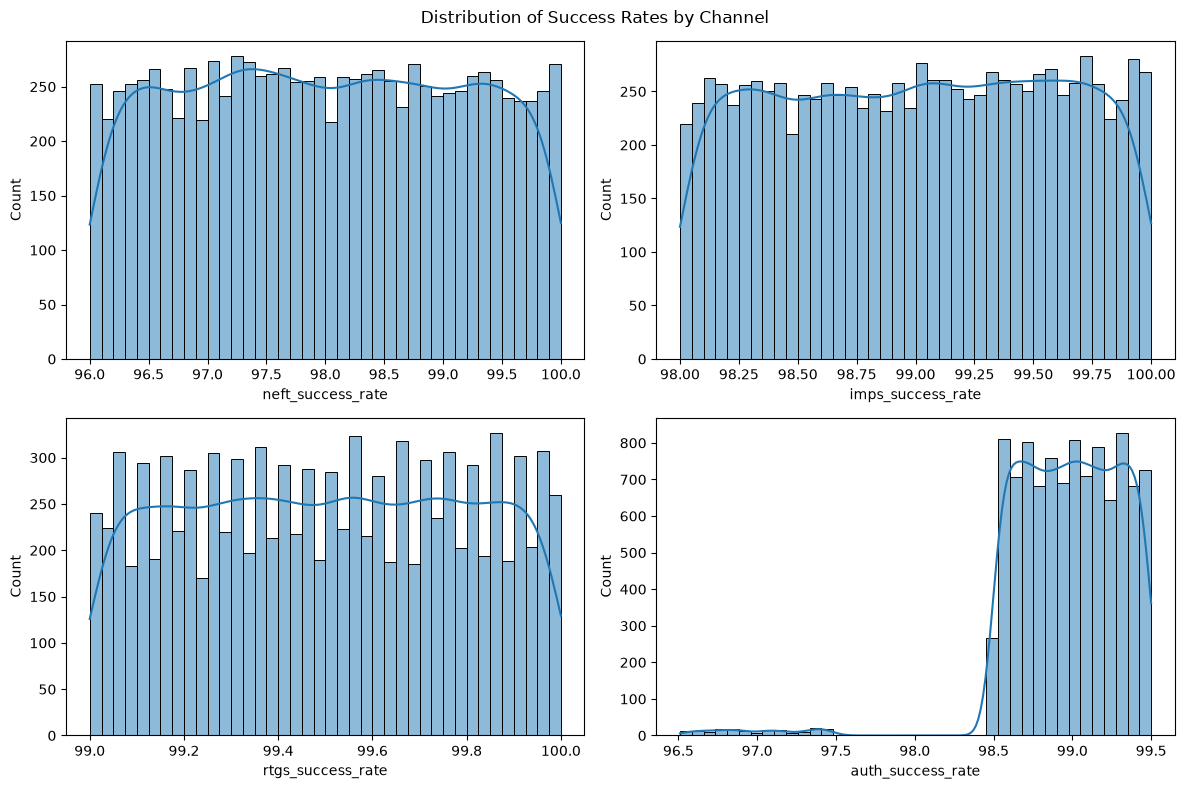

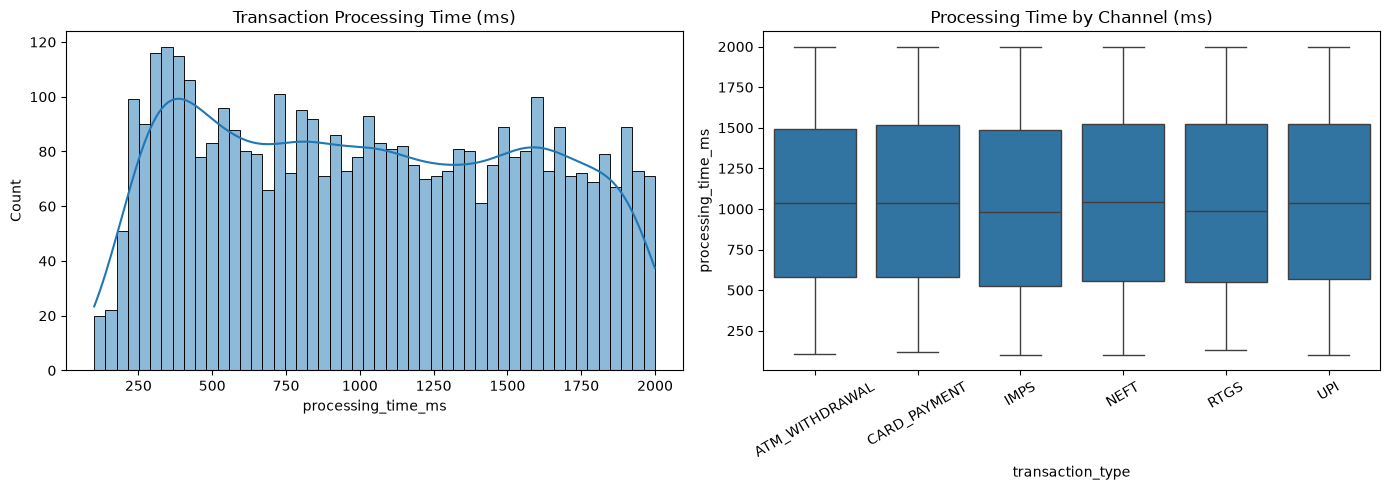

In [3]:
# SECTION 3: Business KPIs (success rates and processing times)

# Success rate columns in the infrastructure file
success_cols = ["neft_success_rate", "imps_success_rate", "rtgs_success_rate", "auth_success_rate"]

# Summary statistics for success rates
print("SUCCESS RATES (%)")
print(infra[success_cols].describe().round(2))

# Share of minutes each rate fell below a 95% degradation threshold
print()
for col in success_cols:
    pct_low = (infra[col] < 95).mean() * 100
    print(col, "below 95% :", round(pct_low, 2), "% of minutes")

# Processing time summaries from both sources
print()
print("TRANSACTION PROCESSING TIME (ms)")
print(transactions["processing_time_ms"].describe().round(2))

print()
print("INFRASTRUCTURE AVG PROCESSING TIME (ms)")
print(infra["avg_transaction_processing_time_ms"].describe().round(2))

# Processing time by channel, including the 95th percentile
print()
print("PROCESSING TIME BY CHANNEL (ms)")
by_channel = transactions.groupby("transaction_type")["processing_time_ms"].agg(["count", "mean", "median", "max"])
by_channel["p95"] = transactions.groupby("transaction_type")["processing_time_ms"].quantile(0.95)
print(by_channel.round(2).sort_values("mean", ascending=False))

# Distribution of each success rate
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(data=infra, x="neft_success_rate", bins=40, kde=True, ax=axes[0, 0])

sns.histplot(data=infra, x="imps_success_rate", bins=40, kde=True, ax=axes[0, 1])

sns.histplot(data=infra, x="rtgs_success_rate", bins=40, kde=True, ax=axes[1, 0])

sns.histplot(data=infra, x="auth_success_rate", bins=40, kde=True, ax=axes[1, 1])

plt.suptitle("Distribution of Success Rates by Channel")
plt.tight_layout()
plt.show()

# Processing time distribution and spread by channel
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=transactions, x="processing_time_ms", bins=50, kde=True, ax=axes[0])
axes[0].set_title("Transaction Processing Time (ms)")

sns.boxplot(data=transactions, x="transaction_type", y="processing_time_ms", ax=axes[1])
axes[1].set_title("Processing Time by Channel (ms)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

INFRASTRUCTURE METRICS
       cpu_utilization  memory_usage  db_connection_pool_usage  \
count         10080.00      10080.00                  10080.00   
mean             49.12         44.19                     39.31   
std              13.36         11.85                     11.83   
min              32.90         30.86                     19.71   
25%              39.07         35.39                     30.11   
50%              42.98         37.79                     36.88   
75%              65.44         60.09                     48.09   
95%              73.17         64.91                     62.01   
99%              75.13         66.19                     65.43   
max              77.52         68.16                     68.06   

       network_throughput_mbps  application_error_rate  service_uptime  
count                 10080.00                10080.00        10080.00  
mean                    245.22                    2.00          100.00  
std                      71.25 

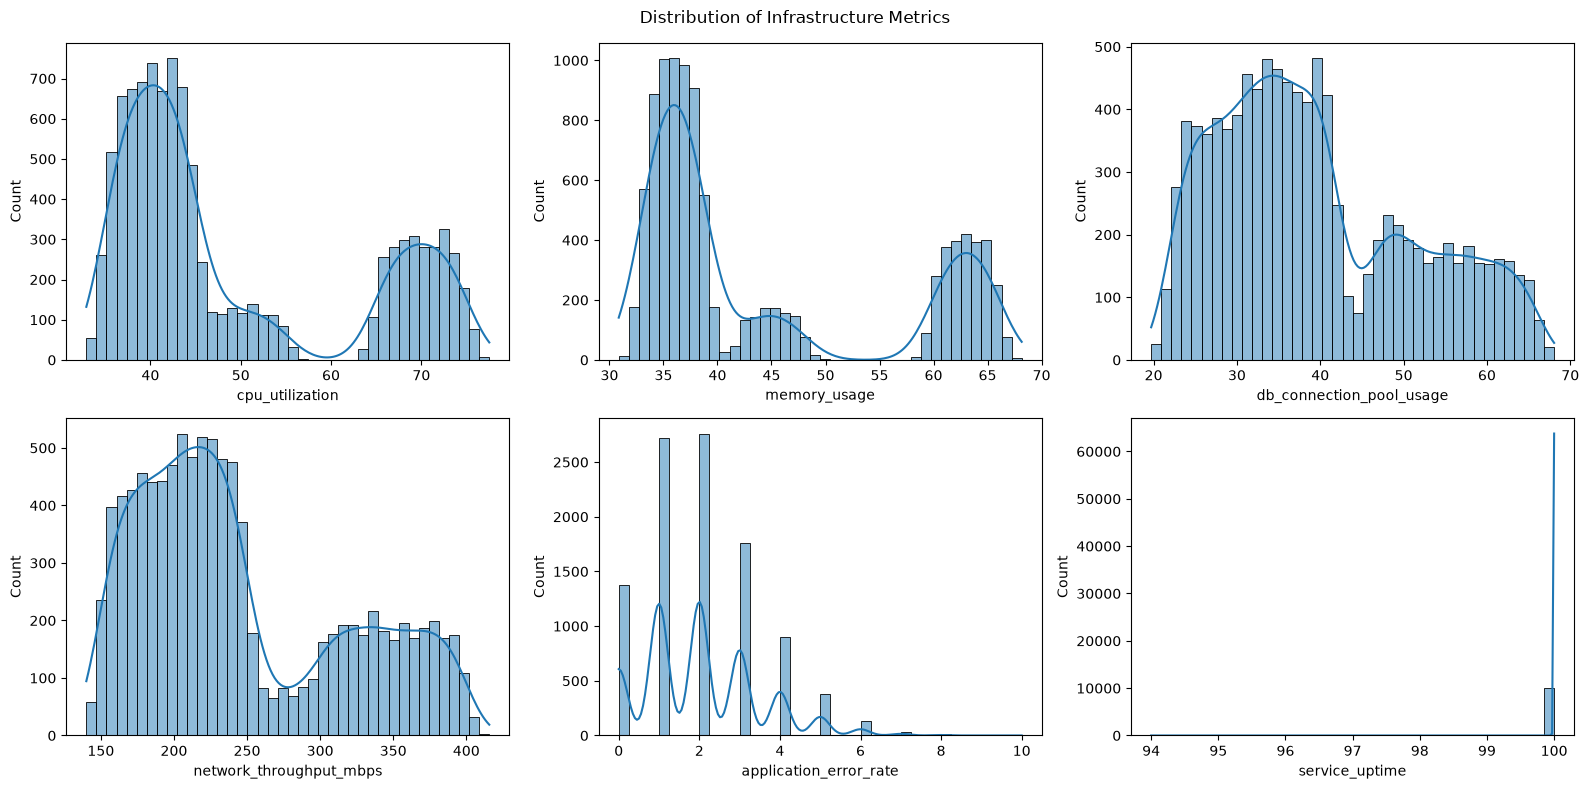

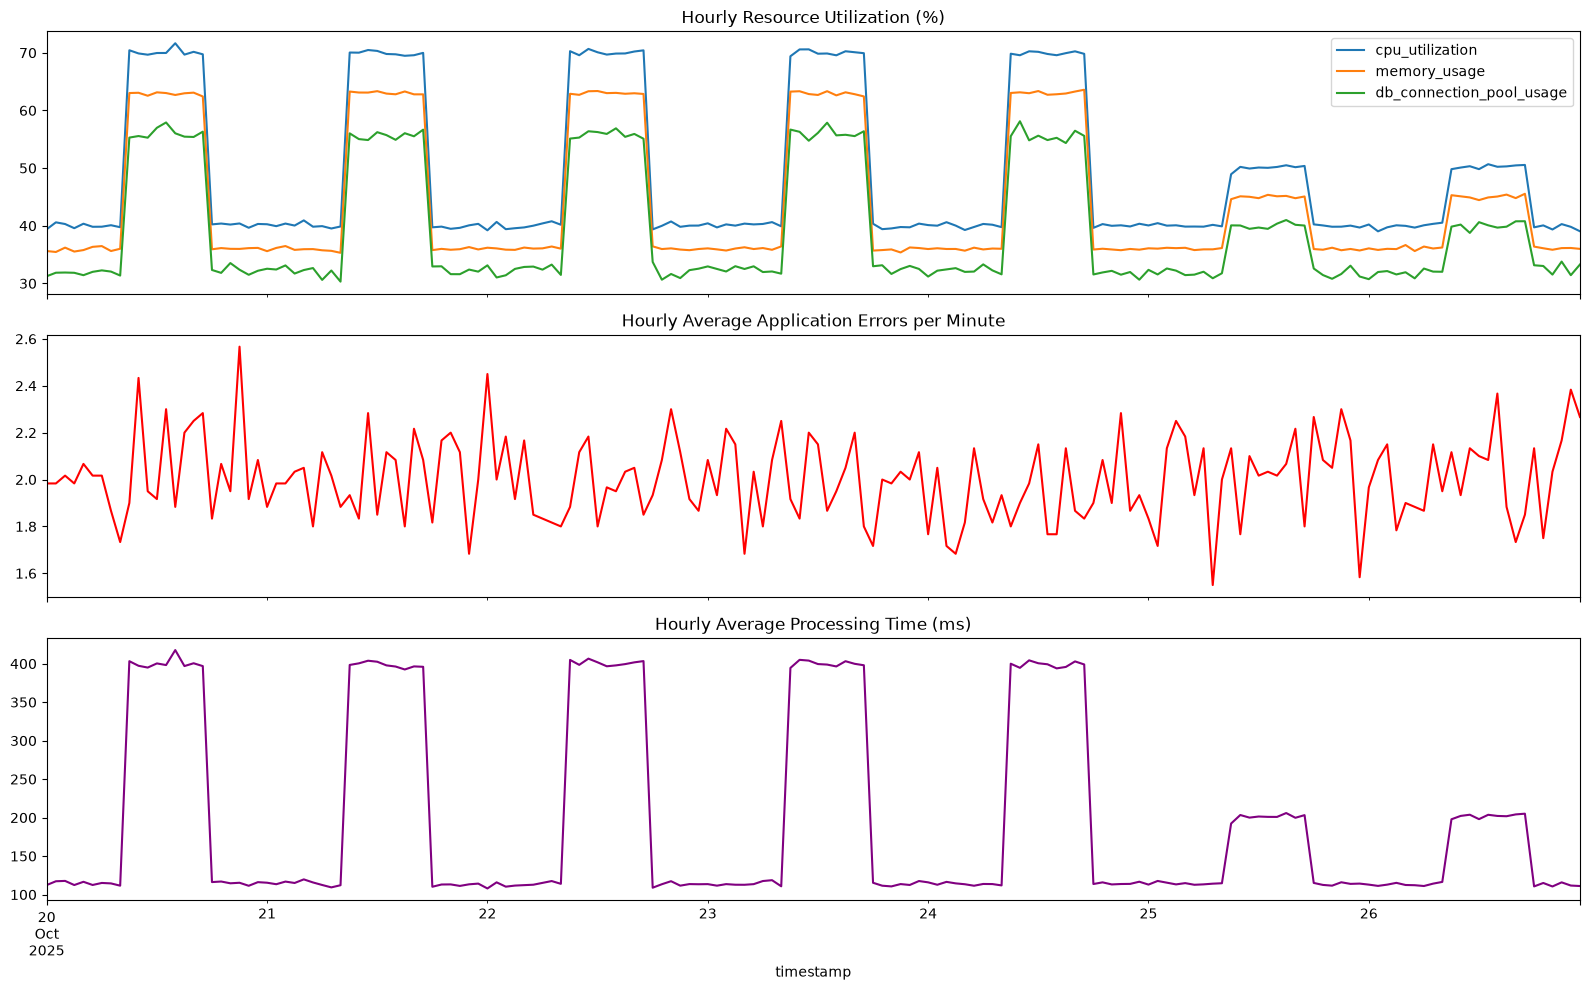

In [4]:
# SECTION 4: Infrastructure metrics (CPU, memory, error rates)

# Infrastructure load columns
infra_cols = ["cpu_utilization", "memory_usage", "db_connection_pool_usage", "network_throughput_mbps", "application_error_rate", "service_uptime"]

# Summary statistics, including upper percentiles
print("INFRASTRUCTURE METRICS")
print(infra[infra_cols].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(2))

# Share of minutes under heavy load
print()
print("CPU above 80% :", round((infra["cpu_utilization"] > 80).mean() * 100, 2), "% of minutes")
print("Memory above 80% :", round((infra["memory_usage"] > 80).mean() * 100, 2), "% of minutes")
print("DB pool above 80% :", round((infra["db_connection_pool_usage"] > 80).mean() * 100, 2), "% of minutes")
print("Uptime below 100% :", round((infra["service_uptime"] < 100).mean() * 100, 2), "% of minutes")

# How many errors occur per minute
print()
print("APPLICATION ERRORS PER MINUTE")
print(infra["application_error_rate"].value_counts().sort_index())

# Distribution of each metric
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for i, col in enumerate(infra_cols):
    sns.histplot(data=infra, x=col, bins=40, kde=True, ax=axes[i // 3, i % 3])

plt.suptitle("Distribution of Infrastructure Metrics")
plt.tight_layout()
plt.show()

# Hourly averages across the 7-day window
hourly = infra.set_index("timestamp").resample("h").mean()

fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)

hourly[["cpu_utilization", "memory_usage", "db_connection_pool_usage"]].plot(ax=axes[0])
axes[0].set_title("Hourly Resource Utilization (%)")

hourly["application_error_rate"].plot(ax=axes[1], color="red")
axes[1].set_title("Hourly Average Application Errors per Minute")

hourly["avg_transaction_processing_time_ms"].plot(ax=axes[2], color="purple")
axes[2].set_title("Hourly Average Processing Time (ms)")

plt.tight_layout()
plt.show()

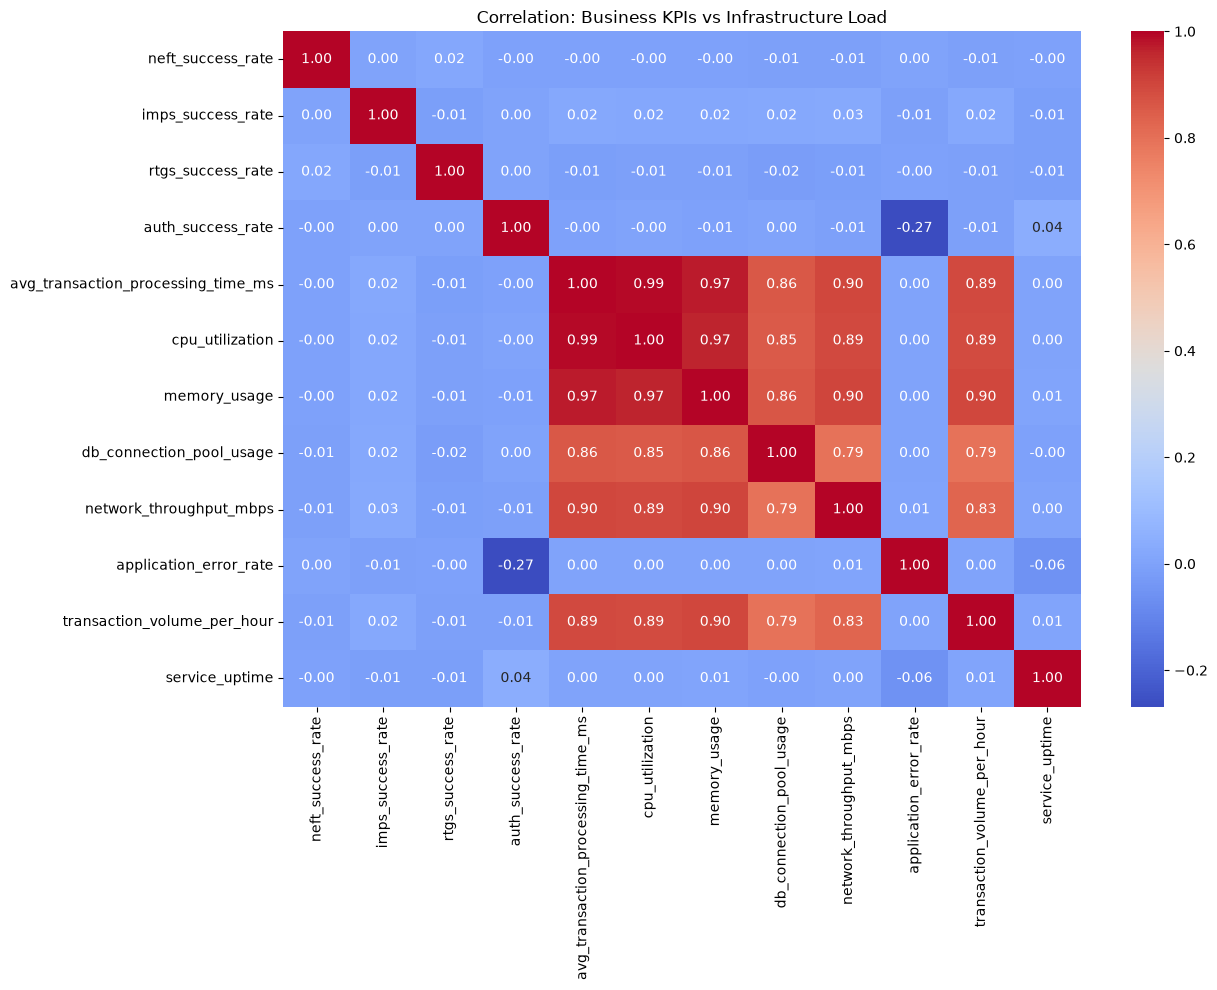

KPI VS LOAD CORRELATION
                                    cpu_utilization  memory_usage  \
neft_success_rate                             -0.00         -0.00   
imps_success_rate                              0.02          0.02   
rtgs_success_rate                             -0.01         -0.01   
auth_success_rate                             -0.00         -0.01   
avg_transaction_processing_time_ms             0.99          0.97   

                                    db_connection_pool_usage  \
neft_success_rate                                      -0.01   
imps_success_rate                                       0.02   
rtgs_success_rate                                      -0.02   
auth_success_rate                                       0.00   
avg_transaction_processing_time_ms                      0.86   

                                    network_throughput_mbps  \
neft_success_rate                                     -0.01   
imps_success_rate                                 

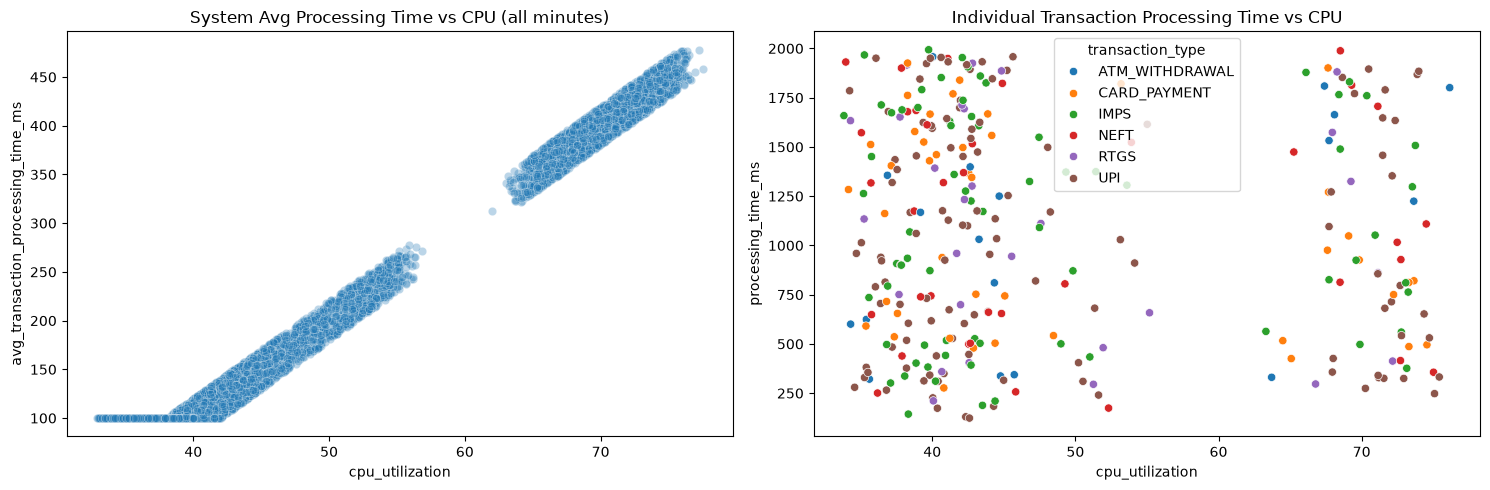

In [5]:
# SECTION 5: Correlate transaction performance with infrastructure load

# Business KPIs and load metrics to compare
kpi_cols = ["neft_success_rate", "imps_success_rate", "rtgs_success_rate", "auth_success_rate", "avg_transaction_processing_time_ms"]

load_cols = ["cpu_utilization", "memory_usage", "db_connection_pool_usage", "network_throughput_mbps", "application_error_rate", "transaction_volume_per_hour"]

# Full correlation matrix for the infrastructure file
corr = infra[kpi_cols + load_cols + ["service_uptime"]].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation: Business KPIs vs Infrastructure Load")
plt.tight_layout()
plt.show()

# KPI rows against load columns only
print("KPI VS LOAD CORRELATION")
print(corr.loc[kpi_cols, load_cols].round(2))

# Transactions that fall inside the infrastructure window
start = infra["timestamp"].min()

end = infra["timestamp"].max()

txn_window = transactions[(transactions["timestamp"] >= start) & (transactions["timestamp"] <= end)].copy()

print()
print("Transactions inside infrastructure window :", len(txn_window))

# Match each transaction to its minute of infrastructure data
txn_window["minute"] = txn_window["timestamp"].dt.floor("min")

merged = txn_window.merge(infra, left_on="minute", right_on="timestamp", how="left", suffixes=("_txn", "_infra"))

print("Transactions matched to a minute :", merged["cpu_utilization"].notnull().sum())

# Correlation of individual transaction processing time with load
print()
print("TRANSACTION PROCESSING TIME VS LOAD")
print(merged[["processing_time_ms"] + load_cols].corr()["processing_time_ms"].round(2))

# Scatter plots: system latency and transaction latency against CPU
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(data=infra, x="cpu_utilization", y="avg_transaction_processing_time_ms", alpha=0.3, ax=axes[0])
axes[0].set_title("System Avg Processing Time vs CPU (all minutes)")

sns.scatterplot(data=merged, x="cpu_utilization", y="processing_time_ms", hue="transaction_type", ax=axes[1])
axes[1].set_title("Individual Transaction Processing Time vs CPU")

plt.tight_layout()
plt.show()

Weekday bottleneck hours (latency above 300 ms) : [9, 10, 11, 12, 13, 14, 15, 16, 17]
Weekend elevated hours (latency above 150 ms) : [9, 10, 11, 12, 13, 14, 15, 16, 17]

Auth success below 98% : 175 minutes
Error spikes (at or above 6.0 per minute) : 175 minutes
Uptime below 100% : 1 minutes

AUTH DROPS BY DAY AND HOUR
timestamp   hour
2025-10-20  0       1
            1       1
            4       1
            13      2
            16      3
                   ..
2025-10-26  18      2
            19      1
            21      1
            22      2
            23      1
Length: 104, dtype: int64

Hourly log ERRORs vs infrastructure errors, correlation : -0.05


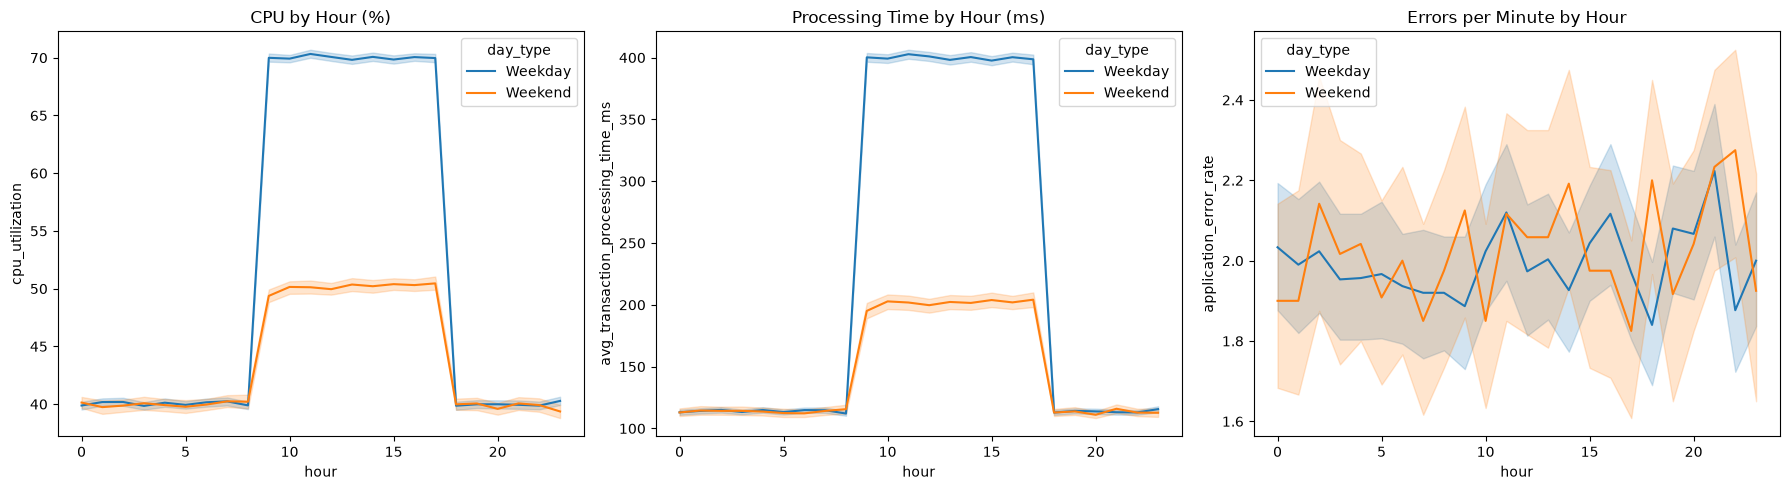

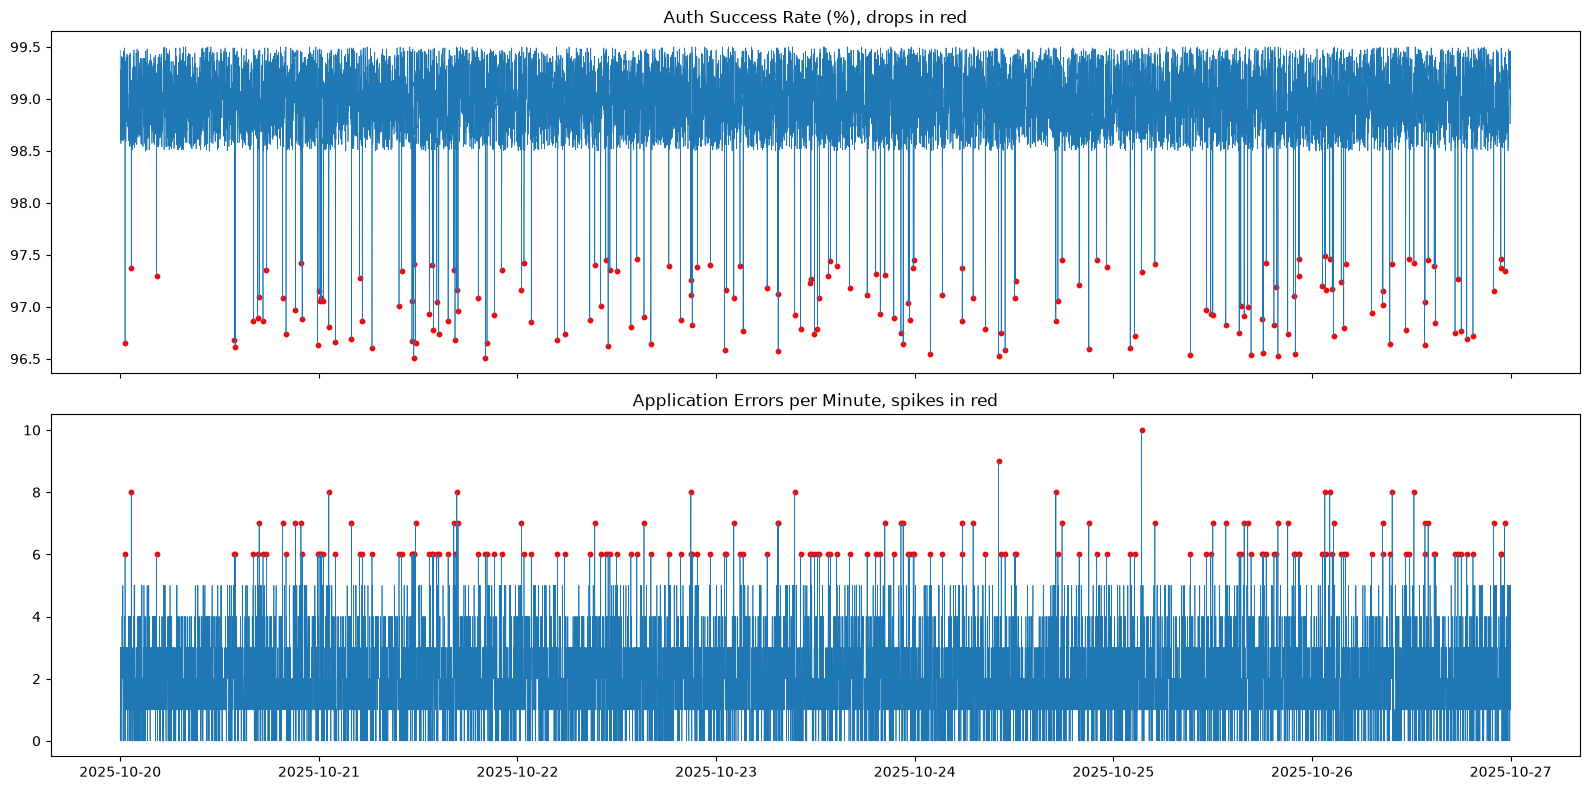

In [7]:
# SECTION 6: Visualize bottlenecks and anomalies

# Time features for daily patterns
infra["hour"] = infra["timestamp"].dt.hour

infra["day_type"] = np.where(infra["timestamp"].dt.day_of_week < 5, "Weekday", "Weekend")

# Average load and latency by hour, weekday vs weekend
profile = infra.groupby(["day_type", "hour"])[["cpu_utilization", "avg_transaction_processing_time_ms", "application_error_rate"]].mean().round(2)

weekday = profile.loc["Weekday"]

print("Weekday bottleneck hours (latency above 300 ms) :", weekday[weekday["avg_transaction_processing_time_ms"] > 300].index.tolist())

weekend = profile.loc["Weekend"]

print("Weekend elevated hours (latency above 150 ms) :", weekend[weekend["avg_transaction_processing_time_ms"] > 150].index.tolist())

# Rule-based anomaly flags
infra["flag_auth_drop"] = infra["auth_success_rate"] < 98

error_cutoff = infra["application_error_rate"].quantile(0.99)

infra["flag_error_spike"] = infra["application_error_rate"] >= error_cutoff

infra["flag_uptime"] = infra["service_uptime"] < 100

print()
print("Auth success below 98% :", infra["flag_auth_drop"].sum(), "minutes")
print("Error spikes (at or above", error_cutoff, "per minute) :", infra["flag_error_spike"].sum(), "minutes")
print("Uptime below 100% :", infra["flag_uptime"].sum(), "minutes")

# When the auth drops happened
print()
print("AUTH DROPS BY DAY AND HOUR")
print(infra[infra["flag_auth_drop"]].groupby([infra["timestamp"].dt.date, "hour"]).size())

# Do logged errors track the infrastructure error count?
log_errors = logs[logs["log_level"] == "ERROR"].set_index("timestamp").resample("h").size()

infra_errors = infra.set_index("timestamp")["application_error_rate"].resample("h").sum()

print()
print("Hourly log ERRORs vs infrastructure errors, correlation :", round(log_errors.corr(infra_errors), 2))

# Hourly profile charts
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.lineplot(data=infra, x="hour", y="cpu_utilization", hue="day_type", ax=axes[0])
axes[0].set_title("CPU by Hour (%)")

sns.lineplot(data=infra, x="hour", y="avg_transaction_processing_time_ms", hue="day_type", ax=axes[1])
axes[1].set_title("Processing Time by Hour (ms)")

sns.lineplot(data=infra, x="hour", y="application_error_rate", hue="day_type", ax=axes[2])
axes[2].set_title("Errors per Minute by Hour")

plt.tight_layout()
plt.show()

# Anomaly timelines with flagged minutes in red
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

axes[0].plot(infra["timestamp"], infra["auth_success_rate"], linewidth=0.5)
flagged = infra[infra["flag_auth_drop"]]
axes[0].scatter(flagged["timestamp"], flagged["auth_success_rate"], color="red", s=10)
axes[0].set_title("Auth Success Rate (%), drops in red")

axes[1].plot(infra["timestamp"], infra["application_error_rate"], linewidth=0.5)
flagged = infra[infra["flag_error_spike"]]
axes[1].scatter(flagged["timestamp"], flagged["application_error_rate"], color="red", s=10)
axes[1].set_title("Application Errors per Minute, spikes in red")

plt.tight_layout()
plt.show()

In [8]:
# SECTION 7: Save cleaned data for modeling

# Do auth drops and error spikes happen in the same minutes?
both = (infra["flag_auth_drop"] & infra["flag_error_spike"]).sum()

print("Minutes with both an auth drop and an error spike :", both)

# Save cleaned datasets, keeping the new time features and flags
transactions.to_csv("data/clean_transactions.csv", index=False)

infra.to_csv("data/clean_infrastructure.csv", index=False)

logs.to_csv("data/clean_logs.csv", index=False)

# Confirm what was saved
print()
print("Saved clean_transactions.csv :", transactions.shape)
print("Saved clean_infrastructure.csv :", infra.shape)
print("Saved clean_logs.csv :", logs.shape)
print()
print("Infrastructure columns :", infra.columns.tolist())

Minutes with both an auth drop and an error spike : 175

Saved clean_transactions.csv : (4000, 10)
Saved clean_infrastructure.csv : (10080, 18)
Saved clean_logs.csv : (4991, 3)

Infrastructure columns : ['timestamp', 'cpu_utilization', 'memory_usage', 'db_connection_pool_usage', 'network_throughput_mbps', 'application_error_rate', 'neft_success_rate', 'imps_success_rate', 'rtgs_success_rate', 'avg_transaction_processing_time_ms', 'auth_success_rate', 'transaction_volume_per_hour', 'service_uptime', 'hour', 'day_type', 'flag_auth_drop', 'flag_error_spike', 'flag_uptime']
